Gradient boosting
Instead of train many deeps trees and average them, we train small trees each one knowing the error of the precedents
so the error is lower in each tree

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

rng = np.random.default_rng(0)
# This is x_train
X_curve = np.sort(rng.uniform(0, 10, 200)).reshape(-1, 1)
# This is y
y_curve = np.sin(X_curve).ravel() + rng.normal(0,0.3, 200)
# This is x_test
grid = np.linspace(0,10,500).reshape(-1, 1)

X_curve.shape, y_curve.shape

((200, 1), (200,))

<function matplotlib.pyplot.show(close=None, block=None)>

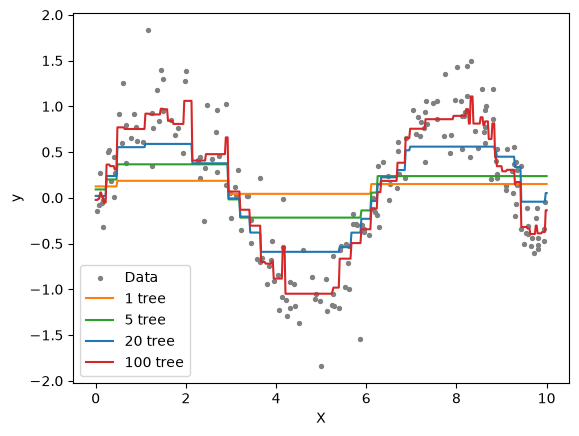

In [12]:
from sklearn.tree import DecisionTreeRegressor

def boost(X, y, n_tree, learning_rate, depth=2):
    starting_value = y.mean()
    prediction = np.full(len(y), starting_value)
    trees = []
    for _ in range(n_tree):
        residuals = y - prediction
        tree = DecisionTreeRegressor(random_state=0, max_depth=depth).fit(X, residuals)
        prediction += learning_rate * tree.predict(X)
        trees.append(tree)
    return starting_value, trees

def predict_boosted(starting_value, trees, learning_rate, X):
    return starting_value + learning_rate * sum(tree.predict(X) for tree in trees)

starting_value, trees = boost(X_curve, y_curve, 100, learning_rate=0.1)
plt.scatter(X_curve, y_curve, s=8, color='gray', label='Data')
for n_trees, color in ((1, 'tab:orange'), (5, 'tab:green'),(20, 'tab:blue'),(100, 'tab:red')):
    plt.plot(grid, predict_boosted(starting_value, trees[:n_trees], 0.1, grid), color=color, label={f"{n_trees} tree"})
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show

### `boost` step by step, with 4 points

`X = [1, 2, 3, 4]`, real `y = [1, 3, 5, 7]`, `max_depth=1`, `learning_rate=0.1`. The model starts at the mean, 4. Each list holds the values for the 4 points, in order.

| Tree | ① Prediction before | ② Residuals = y − ① (what the tree learns) | ③ Tree predicts | ④ Step = 0.1 × ③ | ⑤ Prediction after = ① + ④ | Split used |
|---|---|---|---|---|---|---|
| 1 | [4.00, 4.00, 4.00, 4.00] | [−3.00, −1.00, 1.00, 3.00] | [−2.00, −2.00, 2.00, 2.00] | [−0.20, −0.20, 0.20, 0.20] | [3.80, 3.80, 4.20, 4.20] | x < 2.5 |
| 2 | [3.80, 3.80, 4.20, 4.20] | [−2.80, −0.80, 0.80, 2.80] | [−1.80, −1.80, 1.80, 1.80] | [−0.18, −0.18, 0.18, 0.18] | [3.62, 3.62, 4.38, 4.38] | x < 2.5 |
| 3 | [3.62, 3.62, 4.38, 4.38] | [−2.62, −0.62, 0.62, 2.62] | [−1.62, −1.62, 1.62, 1.62] | [−0.16, −0.16, 0.16, 0.16] | [3.46, 3.46, 4.54, 4.54] | x < 2.5 |
| 4 | [3.46, 3.46, 4.54, 4.54] | [−2.46, −0.46, 0.46, 2.46] | [−1.46, −1.46, 1.46, 1.46] | [−0.15, −0.15, 0.15, 0.15] | [3.31, 3.31, 4.69, 4.69] | x < 2.5 |
| 5 | [3.31, 3.31, 4.69, 4.69] | [−2.31, −0.31, 0.31, 2.31] | [−2.31, 0.77, 0.77, 0.77] | [−0.23, 0.08, 0.08, 0.08] | [3.08, 3.39, 4.76, 4.76] | **x < 1.5** |
| 10 | [2.64, 3.21, 4.79, 5.36] | [−1.64, −0.21, 0.21, 1.64] | [−0.55, −0.55, −0.55, 1.64] | [−0.05, −0.05, −0.05, 0.16] | [2.59, 3.15, 4.74, 5.52] | **x < 3.5** |
| 20 | [1.83, 3.09, 4.91, 6.17] | [−0.83, −0.09, 0.09, 0.83] | [−0.83, 0.28, 0.28, 0.28] | [−0.08, 0.03, 0.03, 0.03] | [1.75, 3.11, 4.94, 6.20] | x < 1.5 |
| 50 | [1.11, 3.01, 4.98, 6.90] | [−0.11, −0.01, 0.02, 0.10] | [−0.11, 0.04, 0.04, 0.04] | [−0.01, 0.00, 0.00, 0.00] | [1.09, 3.02, 4.99, 6.90] | x < 1.5 |
| 100 | [1.00, 3.00, 5.00, 7.00] | ≈ [0, 0, 0, 0] | ≈ [0, 0, 0, 0] | ≈ [0, 0, 0, 0] | **[1.00, 3.00, 5.00, 7.00]** ✅ | x < 1.5 |

**Reading one row** (tree 3, last point, real y = 7): the running total is 4.38, so 7 − 4.38 = 2.62 is missing. The tree predicts 1.62, because x = 3 and x = 4 share a leaf and it gives their average, (0.62 + 2.62) / 2. The step is 0.1 × 1.62 = 0.16, so the total becomes 4.38 + 0.16 = 4.54.

- **Column ⑤ of one row is column ① of the next:** the running total is passed from tree to tree.
- **The split changes (trees 5 and 10):** each tree looks at the current residuals and attacks wherever the most error is left. By tree 5 the middle points are almost right and x = 1 is still far off, so the tree isolates it. That's why the trees differ even though they all see the same X.

### The loop in my own words

We have what we want to know: the real values, `y`. First, the model knows one part: the mean.

Then we ask: if this is what we want to know, and we subtract what we know now, **what is left?** That remainder (the residuals) is what we train the next tree for.

Once that tree is trained, we subtract again what we know now from what we want to know, and ask again: what is left? We train for that, and so on. To predict, we **sum all the pieces**: the mean plus the small correction of every tree.

Two details:
- Each round learns only **part** of what is left: the tree is small, and we only add 10% of what it says (the learning rate). That's why we need many rounds.
- After enough rounds, what is left is mostly **noise**. If we keep training on it, the model learns the noise (overfitting), so we choose the number of trees by checking the error on data the model didn't train on.

### Why it's called *gradient* boosting

**Boosting:** train trees one after another. Each tree learns what the previous ones left (the residuals), and the prediction is the sum of all of them.

**Gradient:** how much the error changes when we change the prediction, and in which direction. It's the **slope** of the error: it says which way is downhill.

Example with one point, using the squared error `(y − prediction)² / 2`:

| Real y | Prediction | Error | Gradient (slope) | Downhill direction |
|---|---|---|---|---|
| 7 | 4.38 | (7 − 4.38)² / 2 = 3.43 | −2.62 | **+2.62** |

The downhill direction, +2.62, is exactly the **residual**, 7 − 4.38. So the residuals in `boost` are not a trick: they point to where the error goes down.

```python
residuals = y - prediction                        # the downhill direction (negative gradient)
prediction += learning_rate * tree.predict(X)     # one small step downhill
```

**Gradient boosting = each tree is a step downhill on the error.** The learning rate is the size of the step.

Why the name, and not just "residual boosting"? With squared error, gradient and residual are the same. With another error measure they aren't: with `loss='absolute_error'`, the downhill direction is just +1 or −1 (is the point above or below the prediction?), and the trees learn that. "Follow the gradient" works for any error measure.

### High vs low learning rate

The learning rate is **how much of each tree's correction we actually apply**: 0.1 applies 10%, 1.0 applies 100%.

**With the 4 points** (real y = [1, 3, 5, 7], starting from 4):

| After tree... | `learning_rate=1.0` | `learning_rate=0.1` |
|---|---|---|
| 1 | [2.00, 2.00, 6.00, 6.00] | [3.80, 3.80, 4.20, 4.20] |
| 2 | [1.00, 2.33, 6.33, 6.33] | [3.62, 3.62, 4.38, 4.38] |
| 3 | [0.78, 2.11, 6.11, 7.00] | [3.46, 3.46, 4.54, 4.54] |

With 1.0 the steps are big but they overshoot: x = 1 goes to 0.78, past the real 1. With 0.1 the model moves slowly, but always in the right direction.

**With the sine data** (70% train / 30% test, `max_depth=2`), test MAE:

| learning_rate | Best test MAE | Reached at tree... | Test MAE with 1000 trees |
|---|---|---|---|
| 1.0 | 0.269 | 12 | 0.347 |
| 0.3 | 0.247 | 20 | 0.347 |
| 0.1 | 0.247 | 91 | 0.332 |
| 0.01 | 0.247 | 933 | 0.248 |

- **High learning rate:** fast (few trees), but its best result is worse. Each tree applies its full correction, noise included, so the model overfits quickly.
- **Low learning rate:** reaches a better result, but needs many more trees, so it is slower.
- **Too many trees overfits with any learning rate.** A low learning rate only delays it.
- 0.247 is about the limit: the noise we added (`rng.normal(0, 0.3)`) can't be predicted.

| | High learning rate | Low learning rate |
|---|---|---|
| Steps | Big, can overshoot | Small, careful |
| Trees needed | Few | Many |
| Speed | Fast | Slow |
| Best possible result | Usually worse | Usually better |
| Overfitting | Comes quickly | Comes later |

**Usual rule:** pick a smallish learning rate (0.05–0.1) and choose the number of trees with test or validation error. The two settings work as a pair: halve the learning rate and you need roughly twice the trees.

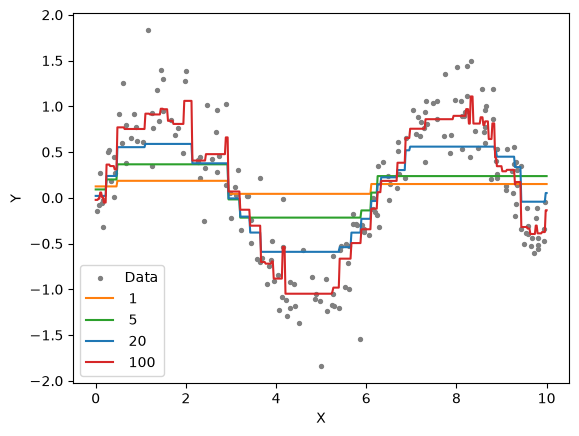

In [13]:
from sklearn.ensemble import GradientBoostingRegressor 

model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=0)
model.fit(X_curve, y_curve)

stages = list(model.staged_predict(grid))

plt.scatter(X_curve, y_curve, s=8, color='gray', label='Data')
for n_trees, color in ((1, 'tab:orange'), (5, 'tab:green'),(20, 'tab:blue'),(100, 'tab:red')):
    plt.plot(grid, stages[n_trees - 1], color=color, label=f" {n_trees}")
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

The learning rate and the number of trees

### `HistGradientBoostingRegressor`

It's the **same algorithm** as `GradientBoostingRegressor`: start at the mean, then fit small trees to the residuals and add them up. What changes is **how each tree looks for its splits**.

- **`GradientBoostingRegressor`** tests **every** possible cut point. California has 12,928 different `MedInc` values, so a split on `MedInc` tests about 12,928 cuts, for every column, at every node, in every tree.
- **`HistGradientBoostingRegressor`** first groups each column into at most **255 ranges (bins)**, like the bars of a **histogram**. For example, all incomes from 3.80 to 3.85 fall in the same bin. Each split then tests only about 255 cuts.

Grouping nearby values loses almost nothing, and it's much faster. On California, with 500 trees of similar size:

| | Training time | Validation MAE |
|---|---|---|
| `GradientBoostingRegressor` | 21.0 s | 31,945 |
| `HistGradientBoostingRegressor` | **0.9 s** | **30,536** |

Other differences:

| | `GradientBoostingRegressor` | `HistGradientBoostingRegressor` |
|---|---|---|
| Number of trees | `n_estimators` | `max_iter` |
| Missing values (NaN) | Must be filled first | Handled by itself |
| Early stopping | Off unless turned on | **On by default** with more than 10,000 rows |
| Best for | Small data | Large data (10,000+ rows) |

That's why the next cell uses `early_stopping=False`: without it, the model would stop before 2000 trees by itself, and the chart couldn't show what happens with too many trees.

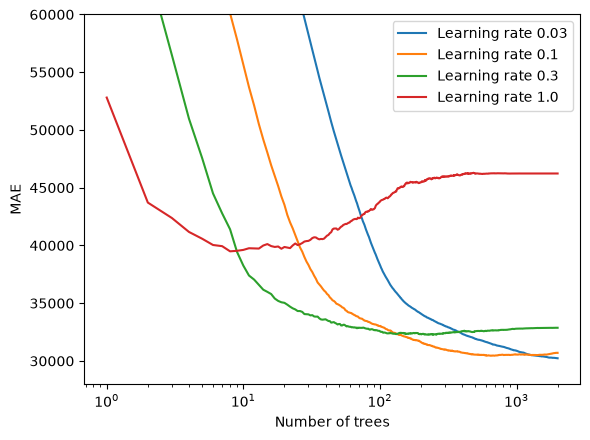

In [14]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import HistGradientBoostingRegressor 
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True).frame
X = housing.drop(columns='MedHouseVal')
y = housing['MedHouseVal']
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_validation, y_train, y_validation = train_test_split(X_rest, y_rest, test_size=0.2, random_state=42)

validation_paths= {}

for learning_rate in ( 0.03, 0.1, 0.3, 1.0):
    model = HistGradientBoostingRegressor(learning_rate=learning_rate, max_iter=2000, early_stopping=False, random_state=42).fit(X_train, y_train)
    validation_paths[learning_rate] = [ 100_000 * mean_absolute_error(y_validation, prediction) for prediction in model.staged_predict(X_validation)]

for learning_rate, path in validation_paths.items():
    plt.plot(range(1 ,len(path) + 1), path, label=f"Learning rate {learning_rate}")

plt.xscale('log')
plt.ylim(28_000, 60_000)
plt.xlabel('Number of trees')
plt.ylabel('MAE')
plt.legend()
plt.show()

In [15]:
pd.DataFrame({
    learning_rate: {
        'Best number of trees': int(np.argmin(path)) + 1,
        'Best validation MAE': min(path),
        'Validation MAE after 2000 trees': path[-1]
        } for learning_rate, path in validation_paths.items()
    }).T.rename_axis('learning rate').round(0)

,Best number of trees,Best validation MAE,Validation MAE after 2000 trees
learning rate,,,
0.03,2000.0,30232.0,30232.0
0.10,655.0,30449.0,30700.0
0.30,227.0,32268.0,32872.0
1.00,8.0,39491.0,46230.0


### Train, validation and test

📺 Video (Spanish): [Los sets de entrenamiento, validación y prueba, by Codificando Bits](https://www.youtube.com/watch?v=79K93XBOsIg)

That's why we call `train_test_split` twice: one split gives 2 groups, and we need 3.

```
20,640 rows
 ├─ 1st split → test: 4,128 (20%)
 └─ rest: 16,512
     ├─ 2nd split → validation: 3,303 (20% of the rest)
     └─ train: 13,209
```

All three groups have the real answers (`y`). What changes is **what we do with each one**:

| Group | What it's for | Who uses it |
|---|---|---|
| **Train** | Builds the model (`fit`) | The model learns from it |
| **Validation** | Compares configurations and chooses one | **We** decide with it |
| **Test** | Gives the final score, **once** | Nobody: we only read it |

**Train builds, validation chooses, test grades.**

#### The steps

1. Make one model per configuration (for example, each learning rate) and train it on **train**. They are separate models, but all use the same train data.
2. Measure each one's error on **validation**, the same rows for all of them, so the comparison is fair.
3. Keep the configuration with the lowest validation error. In the table above: `learning_rate=0.03` with 2000 trees (30,232). `learning_rate=0.1` with 655 trees is almost as good (30,449) with about 3 times fewer trees.
4. Measure that one model on **test**. That's the honest score for new data.

`validation_paths` holds step 2: for each learning rate, the validation error after 1 tree, 2 trees, ..., 2000 trees. Each line in the chart is one path.

#### Predicting doesn't train

`fit(X, y)` builds the trees. `predict(X)` only uses them: the model doesn't change and never sees `y`. So predicting on validation or test can't teach the model anything. They can only leak in **through us**, when we change settings because of what we saw. That's allowed with validation, never with test.

#### Why not choose with the training data?

The model has already seen those answers, so it always says "more complex is better". A decision tree on California:

| `max_depth` | Error on train | Error on validation |
|---|---|---|
| 6 | 47,000 | 51,498 |
| **10** | 31,041 | **44,390** ← best |
| None | **0** ← "perfect" | 48,876 |

With no depth limit the tree **memorizes** every house (error 0 on train), but it gets worse on new houses. Train shows how well it memorized; validation shows how well it learned.

#### Why not choose with test?

The loop would be the same, but the winner wins partly **by luck**: it happens to fit those particular test rows a bit better. Its test score comes out too good, and no unseen data is left to check it. Splitting California into 4 parts and trying 8,000 configurations:

| | Error on test | Error on new data |
|---|---|---|
| Chosen with validation | 30,142 | **29,715** |
| Chosen with test | **30,102** ← looks best | 29,859 |

The model chosen with test looked better but was worse on new data. With lots of data the gap is small. With less data or more configurations, it grows.

#### Can validation be skipped?

- **Yes**, if we don't choose anything (fixed or default settings): train + test is enough.
- **No**, if we compare options. In that case we need validation, done by us, by early stopping (Hist sets aside 10% of train by itself), or by cross-validation.

This works the same for **any algorithm**: `max_depth` in a tree, `n_estimators` in a random forest, and so on. Settings we choose before training are called **hyperparameters**.

Early stopping

In [17]:
early_stopped = HistGradientBoostingRegressor(learning_rate=0.1, max_iter=2000, early_stopping=True, random_state=42).fit(X_train, y_train)
early_stopped.n_iter_, 100_000 * mean_absolute_error(y_validation, early_stopped.predict(X_validation))

(142, 32475.446621653693)

### What early stopping is for

**It chooses the number of trees by itself, in one `fit`.** It sets aside 10% of the train rows as a small validation set of its own. After each tree it measures the error on those rows, and when 10 trees in a row don't improve it, it stops.

It's the same idea as the validation chart above, but automatic and much cheaper:

| | Trees | Validation MAE | Time |
|---|---|---|---|
| Chart: train 2000 trees, then we pick the best | 655 | 30,449 | 3.3 s per learning rate |
| Early stopping (defaults) | 142 | 32,475 | **0.3 s** |

We give up a little accuracy for about 10 times less time. With big data and many configurations to try, that's minutes or hours.

#### Why it scores worse here

1. **It gives up too soon.** By default it stops after 10 trees without improvement (`n_iter_no_change=10`). Around tree 142 the curve was flat for a moment, so it stopped, even though it would have improved later. With more patience:

   | `n_iter_no_change` | Trees | Validation MAE | Time |
   |---|---|---|---|
   | 10 (default) | 142 | 32,475 | 0.3 s |
   | 50 | 525 | 30,691 | 0.9 s |
   | 200 | 771 | 30,621 | 1.3 s |

2. **It trains on fewer rows.** The 10% it sets aside isn't used for training. The cost is small: 142 trees trained on all of train give 32,262 instead of 32,475.

3. **The comparison isn't fully fair.** We chose 655 trees by looking at the validation curve, so 30,449 is a bit optimistic (the same problem as choosing with test, one level down). Early stopping never saw our validation set, so 32,475 is an honest score.

**In short:** early stopping isn't meant to beat a careful search. It finds a good number of trees quickly and on its own. If it stops too early, raise `n_iter_no_change`.

Against a Random forest

In [9]:
import time 
from sklearn.ensemble import RandomForestRegressor

contenders ={
        "random forest 100 trees": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        "gradient boosting, default": HistGradientBoostingRegressor(random_state=42),
        "gradient boosting, 2000 trees": HistGradientBoostingRegressor(max_iter=2000, random_state=42, early_stopping=True)
    }
comparasion = {}

for name, model in contenders.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    comparasion[name] = {
            "seconds to train": time.perf_counter() - start,
            "validation MAE ($)": 100_000 * mean_absolute_error(y_validation, model.predict(X_validation))
            }
pd.DataFrame(comparasion).T.round(1)

,seconds to train,validation MAE ($)
random forest 100 trees,0.6,34475.2
"gradient boosting, default",0.2,32995.2
"gradient boosting, 2000 trees",0.3,32475.4


What HistGradientBoostingRegressor adds
The histogram based gradient boost first sort each feature into almost 255 bins, and
then only considers the borders between them, faster with almost no loss of accuracy.
It also brings what tables of real data needs:
    - Missing values as they are , no imputation is needed
    - Categories can be uses directly with categorical_features
    - Early stopping is built in